In [1]:
import numpy as np
import pandas as pd

In [2]:
train_df = pd.read_csv('data.csv')
train_df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP002529,Male,Yes,2,Graduate,No,6700,1750.0,230.0,300.0,1.0,Semiurban,Y
1,LP001385,Male,No,0,Graduate,No,5316,0.0,136.0,360.0,1.0,Urban,Y
2,LP001926,Male,Yes,0,Graduate,No,3704,2000.0,120.0,360.0,1.0,Rural,Y
3,LP001144,Male,Yes,0,Graduate,No,5821,0.0,144.0,360.0,1.0,Urban,Y
4,LP002562,Male,Yes,1,Not Graduate,No,5333,1131.0,186.0,360.0,NaN,Urban,Y


In [3]:
train_df.shape

(430, 13)

In [4]:
train_df['Gender']= train_df['Gender'].map({'Male':0, 'Female':1})
train_df['Married']= train_df['Married'].map({'No':0, 'Yes':1})
train_df['Loan_Status']= train_df['Loan_Status'].map({'N':0, 'Y':1})

train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 430 entries, 0 to 429
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            430 non-null    str    
 1   Gender             420 non-null    float64
 2   Married            427 non-null    float64
 3   Dependents         416 non-null    str    
 4   Education          430 non-null    str    
 5   Self_Employed      410 non-null    str    
 6   ApplicantIncome    430 non-null    int64  
 7   CoapplicantIncome  430 non-null    float64
 8   LoanAmount         414 non-null    float64
 9   Loan_Amount_Term   422 non-null    float64
 10  Credit_History     394 non-null    float64
 11  Property_Area      430 non-null    str    
 12  Loan_Status        430 non-null    int64  
dtypes: float64(6), int64(2), str(5)
memory usage: 55.1 KB


In [5]:
train_df.isna().sum()

Loan_ID               0
Gender               10
Married               3
Dependents           14
Education             0
Self_Employed        20
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           16
Loan_Amount_Term      8
Credit_History       36
Property_Area         0
Loan_Status           0
dtype: int64

In [6]:
train_df = train_df.dropna()
train_df.isnull().sum()

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64

In [7]:
train_df.shape

(335, 13)

In [8]:
X = train_df[['Gender', 'Married', 'ApplicantIncome', 'LoanAmount', 'Credit_History']]
y = train_df.Loan_Status
X.shape, y.shape

((335, 5), (335,))

In [9]:
X.head()

,Gender,Married,ApplicantIncome,LoanAmount,Credit_History
0,0.0,1.0,6700,230.0,1.0
1,0.0,0.0,5316,136.0,1.0
2,0.0,1.0,3704,120.0,1.0
3,0.0,1.0,5821,144.0,1.0
5,0.0,1.0,3052,100.0,1.0


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=5)

In [11]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(max_depth=4, random_state=5)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",5
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: 

In [12]:
model.score(X_val, y_val)

0.7313432835820896

In [13]:
model.score(X_train, y_train)

0.8134328358208955

# MLFLOW

In [14]:
# !pip install mlflow

In [15]:
import mlflow

In [16]:
# set the experiment name - Project level. All the runs will be logged under this experiment.
mlflow.set_experiment("Loan-Default-Prediction")

2026/10/14 13:52:56 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/14 13:52:56 INFO mlflow.store.db.utils: Updating database tables
2026/10/14 13:52:56 INFO mlflow.tracking.fluent: Experiment with name 'Loan-Default-Prediction' does not exist. Creating a new experiment.


<Experiment: artifact_location='/Users/thekashishbhagat/Documents/scaler/batches/Flask-Apr-26/Flask-Sept-26/mlruns/1', creation_time=1791966176809, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791966176809, lifecycle_stage='active', name='Loan-Default-Prediction', tags={}, trace_location=None, workspace='default'>

In [18]:
# Start an MLflow run
with mlflow.start_run():

    model = RandomForestClassifier(max_depth=4, random_state=5)
    model.fit(X_train, y_train)

    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)

    mlflow.set_tag("mlflow.runName", "first_run")

    # Log parameters, metrics, and model to MLflow
    mlflow.log_param("max_depth", 4)
    mlflow.log_metric("train_accuracy", train_acc)
    mlflow.log_metric("val_accuracy", val_acc)

    # Log the model
    mlflow.sklearn.log_model(model, "rf_model",serialization_format="pickle")

2026/10/14 13:54:43 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/14 13:54:43 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [19]:
!mlflow ui --port 5555

Backend store URI not provided. Using sqlite:///mlflow.db
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts and --cors-allowed-origins.
2026/10/14 13:55:52 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/10/14 13:55:52 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
2026/10/14 13:55:52 INFO:     Uvicorn running on http://127.0.0.1:5555 (Press CTRL+C to quit)
2026/10/14 13:55:52 INFO:     Started parent process [4265]
/Users/thekashishbhagat/Documents/scaler/batches/Flask-Apr-26/Flask-Sept-26/mlops_env/lib/python3.14/site-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as

In [20]:
# Start an MLflow run
with mlflow.start_run():

    model = RandomForestClassifier(max_depth=6, random_state=5)
    model.fit(X_train, y_train)

    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)

    mlflow.set_tag("mlflow.runName", "second_run")
    mlflow.set_tag("description", "rf with max_depth 6")

    # Log parameters, metrics, and model to MLflow
    mlflow.log_param("max_depth", 6)
    mlflow.log_metric("train_accuracy", train_acc)
    mlflow.log_metric("val_accuracy", val_acc)

    # Log the model
    mlflow.sklearn.log_model(model, "rf_model",serialization_format="pickle")

2026/10/14 13:57:01 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/14 13:57:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [21]:
!mlflow ui --port 5555

Backend store URI not provided. Using sqlite:///mlflow.db
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts and --cors-allowed-origins.
2026/10/14 13:57:05 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/10/14 13:57:05 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
2026/10/14 13:57:06 INFO:     Uvicorn running on http://127.0.0.1:5555 (Press CTRL+C to quit)
2026/10/14 13:57:06 INFO:     Started parent process [4532]
/Users/thekashishbhagat/Documents/scaler/batches/Flask-Apr-26/Flask-Sept-26/mlops_env/lib/python3.14/site-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as

In [24]:
def mlflow_runs(n_est, max_depth, i):
    with mlflow.start_run():

        model = RandomForestClassifier(n_estimators=n_est, max_depth=max_depth, random_state=5)
        model.fit(X_train, y_train)

        train_acc = model.score(X_train, y_train)
        val_acc = model.score(X_val, y_val)

        run_name = "hyperparam_run_" + str(i)

        mlflow.set_tag("mlflow.runName",run_name)

        # Log parameters, metrics, and model to MLflow
        mlflow.log_param("n_estimators", n_est)
        mlflow.log_param("max_depth", max_depth)
        mlflow.log_metric("train_accuracy", train_acc)
        mlflow.log_metric("val_accuracy", val_acc)

        # Log the model
        mlflow.sklearn.log_model(model, "rf_model",serialization_format="pickle")

In [25]:
mlflow_runs(10, 2, 1)
mlflow_runs(20, 2, 2)
mlflow_runs(40, 2, 3)
mlflow_runs(10, 4, 4)
mlflow_runs(20, 4, 5)
mlflow_runs(40, 4, 6)
mlflow_runs(10, 8, 7)
mlflow_runs(20, 8, 8)
mlflow_runs(40, 8, 9)

2026/10/14 13:58:03 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/14 13:58:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/10/14 13:58:04 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/14 13:58:04 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_p

In [26]:
!mlflow ui --port 5555

Backend store URI not provided. Using sqlite:///mlflow.db
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts and --cors-allowed-origins.
2026/10/14 13:58:22 INFO mlflow.server.jobs.executor_registry: Available backends after discovery: local
2026/10/14 13:58:22 INFO mlflow.server.jobs.executor_registry: Job executor backend 'local' passed requirements check
2026/10/14 13:58:22 INFO:     Uvicorn running on http://127.0.0.1:5555 (Press CTRL+C to quit)
2026/10/14 13:58:22 INFO:     Started parent process [4831]
/Users/thekashishbhagat/Documents/scaler/batches/Flask-Apr-26/Flask-Sept-26/mlops_env/lib/python3.14/site-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as

## New Data

In [26]:
train_df = pd.read_csv('data_new.csv')
train_df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [27]:
train_df.shape

(614, 13)

In [28]:
train_df['Gender']= train_df['Gender'].map({'Male':0, 'Female':1})
train_df['Married']= train_df['Married'].map({'No':0, 'Yes':1})
train_df['Loan_Status']= train_df['Loan_Status'].map({'N':0, 'Y':1})

train_df = train_df.dropna()

In [29]:
X = train_df[['Gender', 'Married', 'ApplicantIncome', 'LoanAmount', 'Credit_History']]
y = train_df.Loan_Status
X.shape, y.shape

((480, 5), (480,))

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=5)

In [32]:
X_train.shape

(384, 5)

In [33]:
# Start an MLflow run
description = "Model trained on new data collected after 1 month"
with mlflow.start_run(description=description):
    model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=5)
    model.fit(X_train, y_train) # new data..
    
    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)

    mlflow.set_tag('mlflow.runName', 'new_data_run')
    mlflow.set_tag('training_info', 'data collection')

    # Log parameters
    mlflow.log_param("max_depth", 6)
    mlflow.log_param("n_estimators", 100)
    mlflow.log_metric("train_accuracy", train_acc)
    mlflow.log_metric("val_accuracy", val_acc)

    # Log the model
    mlflow.sklearn.log_model(model, "my_model")

2026/04/21 08:29:56 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


In [34]:
!mlflow ui --port 5555

[2026-04-21 08:30:06 +0530] [5432] [INFO] Starting gunicorn 23.0.0
[2026-04-21 08:30:06 +0530] [5432] [INFO] Listening at: http://127.0.0.1:5555 (5432)
[2026-04-21 08:30:06 +0530] [5432] [INFO] Using worker: sync
[2026-04-21 08:30:06 +0530] [5433] [INFO] Booting worker with pid: 5433
[2026-04-21 08:30:06 +0530] [5434] [INFO] Booting worker with pid: 5434
[2026-04-21 08:30:06 +0530] [5435] [INFO] Booting worker with pid: 5435
[2026-04-21 08:30:06 +0530] [5436] [INFO] Booting worker with pid: 5436
^C

Aborted!
[2026-04-21 08:32:23 +0530] [5433] [INFO] Worker exiting (pid: 5433)
[2026-04-21 08:32:23 +0530] [5434] [INFO] Worker exiting (pid: 5434)
[2026-04-21 08:32:23 +0530] [5436] [INFO] Worker exiting (pid: 5436)
[2026-04-21 08:32:23 +0530] [5435] [INFO] Worker exiting (pid: 5435)


## New Model

In [37]:
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

2026/04/21 08:35:46 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


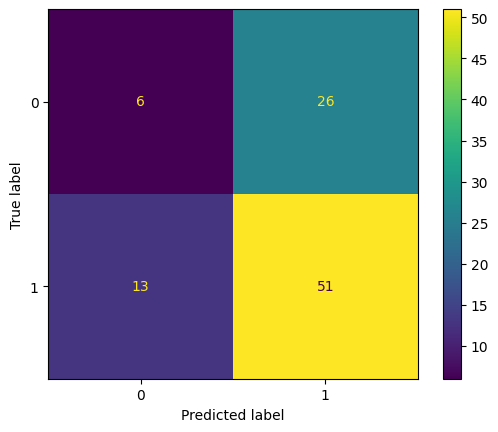

In [38]:
# Start an MLflow run
description = "Model trained on new data collected"
with mlflow.start_run(description=description):
    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train, y_train) # new data..
    
    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)

    mlflow.set_tag('mlflow.runName', 'kNN_run')

    # Log parameters
    mlflow.log_param("n_neighbors", 5)
    mlflow.log_metric("train_accuracy", train_acc)
    mlflow.log_metric("val_accuracy", val_acc)

    cm = ConfusionMatrixDisplay.from_estimator(model, X_val, y_val)
    plt.savefig("confusion_matrix.png")
    mlflow.log_artifact("confusion_matrix.png")
    

    # Log the model
    mlflow.sklearn.log_model(model, "my_model")

In [39]:
!mlflow ui --port 5555

[2026-04-21 08:35:53 +0530] [5635] [INFO] Starting gunicorn 23.0.0
[2026-04-21 08:35:53 +0530] [5635] [INFO] Listening at: http://127.0.0.1:5555 (5635)
[2026-04-21 08:35:53 +0530] [5635] [INFO] Using worker: sync
[2026-04-21 08:35:53 +0530] [5636] [INFO] Booting worker with pid: 5636
[2026-04-21 08:35:53 +0530] [5637] [INFO] Booting worker with pid: 5637
[2026-04-21 08:35:54 +0530] [5638] [INFO] Booting worker with pid: 5638
[2026-04-21 08:35:54 +0530] [5640] [INFO] Booting worker with pid: 5640
^C

Aborted!
[2026-04-21 08:51:59 +0530] [5640] [INFO] Worker exiting (pid: 5640)
[2026-04-21 08:51:59 +0530] [5637] [INFO] Worker exiting (pid: 5637)
[2026-04-21 08:51:59 +0530] [5636] [INFO] Worker exiting (pid: 5636)
[2026-04-21 08:51:59 +0530] [5638] [INFO] Worker exiting (pid: 5638)
